In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:

file_path = "/content/TED_Talks_Cleaned_Dataset.csv"

df = pd.read_csv(file_path)

print("Cleaned TED Talks dataset loaded successfully!")

Cleaned TED Talks dataset loaded successfully!


In [5]:
# Display the first five rows
display(df.head())

,Talk_Id,Title,Speaker_1,All_Speakers,Occupations,About_speakers,Views,Recorded_date,Published_date,Event,Native_lang,Available_lang,Comments,Duration,Topics,Related_talks,URL,Description,Transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,25-02-2006,27-06-2006,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,22-02-2006,27-06-2006,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,24-02-2006,27-06-2006,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,26-02-2006,27-06-2006,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,25-02-2006,27-06-2006,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [6]:
# Display the number of rows and columns
rows, columns = df.shape

print("Number of Rows:", rows)
print("Number of Columns:", columns)

Number of Rows: 4016
Number of Columns: 19


In [12]:
# Display all column names
print("Dataset Columns:\n")

for column in df.columns:
    print(column)

df.info()

Dataset Columns:

Talk_Id
Title
Speaker_1
All_Speakers
Occupations
About_speakers
Views
Recorded_date
Published_date
Event
Native_lang
Available_lang
Comments
Duration
Topics
Related_talks
URL
Description
Transcript
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4016 entries, 0 to 4015
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Talk_Id         4016 non-null   object
 1   Title           4016 non-null   object
 2   Speaker_1       4016 non-null   object
 3   All_Speakers    4016 non-null   object
 4   Occupations     4016 non-null   object
 5   About_speakers  4016 non-null   object
 6   Views           4016 non-null   object
 7   Recorded_date   4016 non-null   object
 8   Published_date  4016 non-null   object
 9   Event           4016 non-null   object
 10  Native_lang     4016 non-null   object
 11  Available_lang  4016 non-null   object
 12  Comments        4016 non-null   object
 13  Duration    

In [32]:
# Count missing values in every column
missing_values = df.isnull().sum()

# Calculate missing-value percentages
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Combine the results into a DataFrame
missing_summary = pd.DataFrame({
    "Missing_Values": missing_values,
    "Missing_Percentage": missing_percentage
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing_Values"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Values,Missing_Percentage
Comments,666,16.583665
Views,11,0.273904
Duration,11,0.273904


*Statistical Part* :

---




In [15]:
# Convert columns that should be numeric to proper numerical data types
numeric_cols = ['Views', 'Comments', 'Duration']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Select numerical columns
numerical_data = df.select_dtypes(include="number")

# Generate descriptive statistics
if not numerical_data.empty:
    display(numerical_data.describe().T)
else:
    print("No numerical columns found in the dataset.")

,count,mean,std,min,25%,50%,75%,max
Views,4005.0,2.148006e+06,3.451226e+06,0.0,882069.0,1375508.0,2133110.0,65051954.0
Comments,3350.0,1.619970e+02,2.688389e+02,0.0,38.0,89.0,188.0,6449.0
Duration,4005.0,7.240112e+02,3.617755e+02,60.0,393.0,738.0,974.0,3922.0


In [16]:
# Convert Views to numeric values
df["Views"] = pd.to_numeric(df["Views"], errors="coerce")

# Display descriptive statistics for Views
display(df["Views"].describe())

,Views
count,4.005000e+03
mean,2.148006e+06
std,3.451226e+06
min,0.000000e+00
25%,8.820690e+05
50%,1.375508e+06
75%,2.133110e+06
max,6.505195e+07


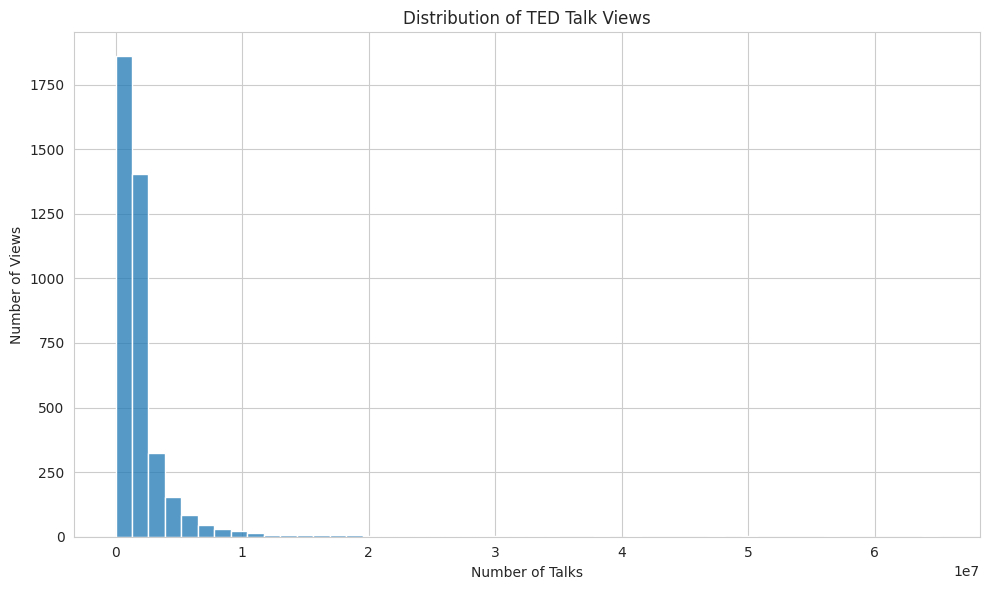

In [33]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Views",
    bins=50
)

plt.title("Distribution of TED Talk Views")
plt.xlabel("Number of Talks")
plt.ylabel("Number of Views")

plt.tight_layout()
plt.show()

In [18]:
# Remove records without valid view counts
views_data = df.dropna(subset=["Views"])

# Identify the 10 most viewed TED Talks
top_10_talks = views_data.nlargest(10, "Views")

# Select relevant columns that exist in the dataset
columns_to_display = [
    col for col in ["Title", "Speaker_1", "Views", "Event"]
    if col in df.columns
]

display(top_10_talks[columns_to_display])

,Title,Speaker_1,Views,Event
4,Do schools kill creativity?,Sir Ken Robinson,65051954.0,TED2006
1297,Your body language may shape who you are,Amy Cuddy,57074270.0,TEDGlobal 2012
2063,This is what happens when you reply to spam email,James Veitch,56932551.0,TEDGlobal>Geneva
647,How great leaders inspire action,Simon Sinek,49730580.0,TEDxPuget Sound
797,The power of vulnerability,Brené Brown,47544833.0,TEDxHouston
1725,How to speak so that people want to listen,Julian Treasure,41504331.0,TEDGlobal 2013
2109,Inside the mind of a master procrastinator,Tim Urban,37976820.0,TED2016
1367,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546.0,TEDxMidAtlantic
2728,My philosophy for a happy life,Sam Berns,33691484.0,TEDxMidAtlantic 2013
1899,The next outbreak? We're not ready,Bill Gates,33521780.0,TED2015


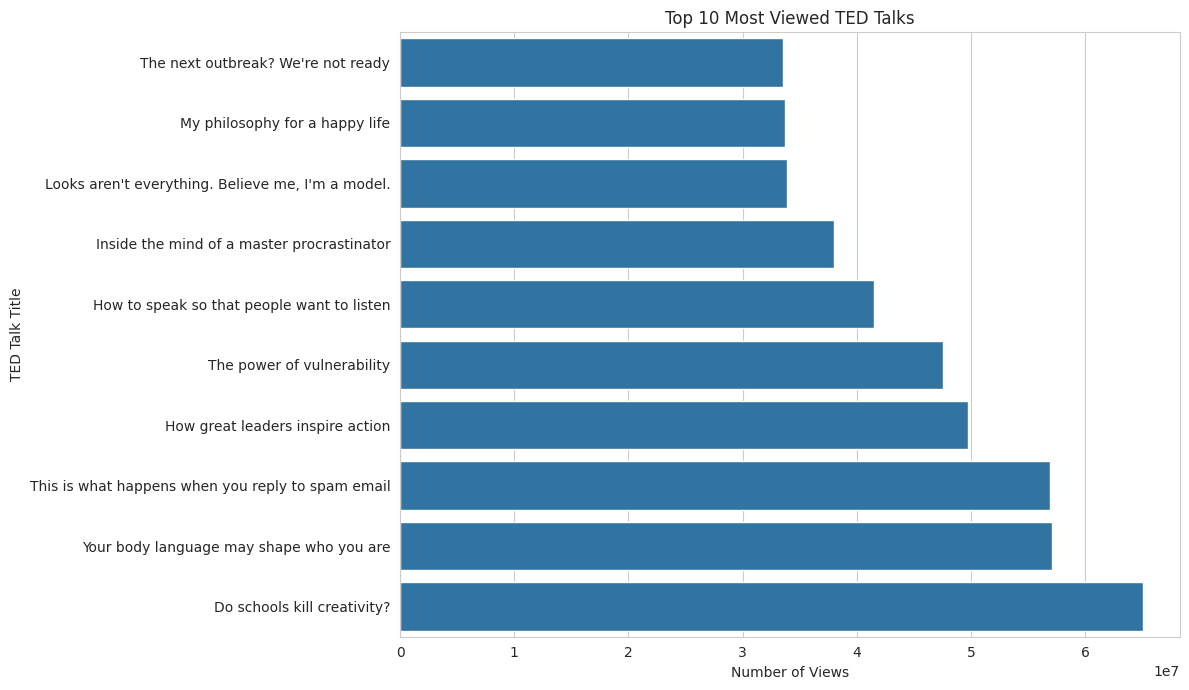

In [19]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_talks.sort_values("Views", ascending=True),
    x="Views",
    y="Title"
)

plt.title("Top 10 Most Viewed TED Talks")
plt.xlabel("Number of Views")
plt.ylabel("TED Talk Title")

plt.tight_layout()
plt.show()

In [20]:
# Select records with available topic information
topics_data = df.dropna(subset=["Topics"]).copy()

# Split each topic string into individual topics
topics_data["Topics"] = (
    topics_data["Topics"]
    .astype(str)
    .str.split(",")
)

# Create one row for each individual topic
topics_exploded = topics_data.explode("Topics")

# Remove extra spaces
topics_exploded["Topics"] = (
    topics_exploded["Topics"].str.strip()
)

# Remove empty topic labels
topics_exploded = topics_exploded[
    topics_exploded["Topics"] != ""
]

# Count the 15 most frequent topics
top_topics = topics_exploded["Topics"].value_counts().head(15)

display(top_topics)

,count
Topics,
'science',816
'technology',619
'culture',522
'global issues',511
'society',462
'social change',439
'design',429
'health',357
'humanity',354


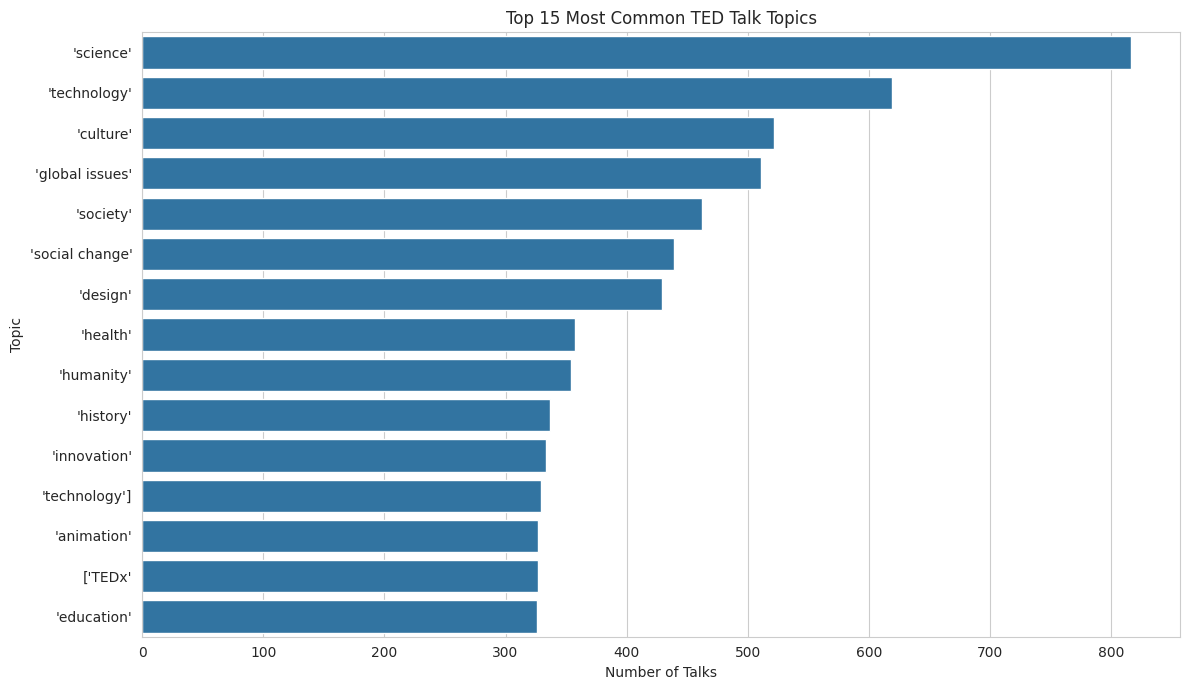

In [21]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_topics.values,
    y=top_topics.index
)

plt.title("Top 15 Most Common TED Talk Topics")
plt.xlabel("Number of Talks")
plt.ylabel("Topic")

plt.tight_layout()
plt.show()

In [22]:
if "Speaker_1" in df.columns:

    speakers_data = df.dropna(subset=["Speaker_1"])

    top_speakers = speakers_data["Speaker_1"].value_counts().head(10)

    display(top_speakers)

else:
    print("The column 'Speaker_1' was not found.")

,count
Speaker_1,
Alex Gendler,34
Iseult Gillespie,19
Emma Bryce,12
Daniel Finkel,11
Hans Rosling,10
Alex Rosenthal,10
Greg Gage,9
Juan Enriquez,9
Chris Anderson,8


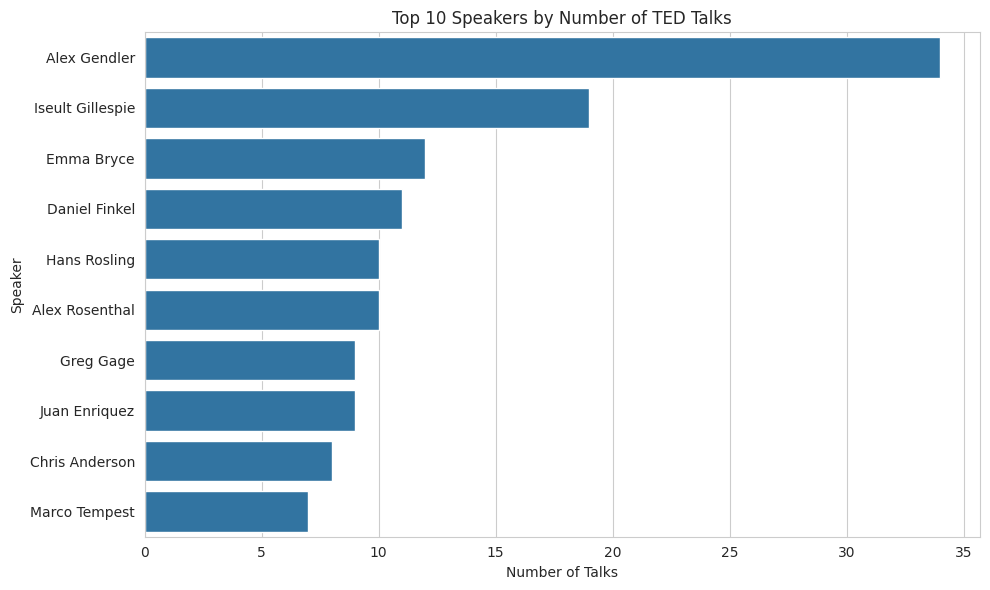

In [23]:
if "Speaker_1" in df.columns:

    plt.figure(figsize=(10, 6))

    sns.barplot(
        x=top_speakers.values,
        y=top_speakers.index
    )

    plt.title("Top 10 Speakers by Number of TED Talks")
    plt.xlabel("Number of Talks")
    plt.ylabel("Speaker")

    plt.tight_layout()
    plt.show()

In [24]:
# Convert columns to numeric
df["Views"] = pd.to_numeric(df["Views"], errors="coerce")
df["Comments"] = pd.to_numeric(df["Comments"], errors="coerce")

# Select records with both values available
engagement_data = df.dropna(subset=["Views", "Comments"])

# Calculate Pearson correlation
correlation = engagement_data["Views"].corr(
    engagement_data["Comments"]
)

print("Correlation between Views and Comments:", correlation)

Correlation between Views and Comments: 0.500748176308322


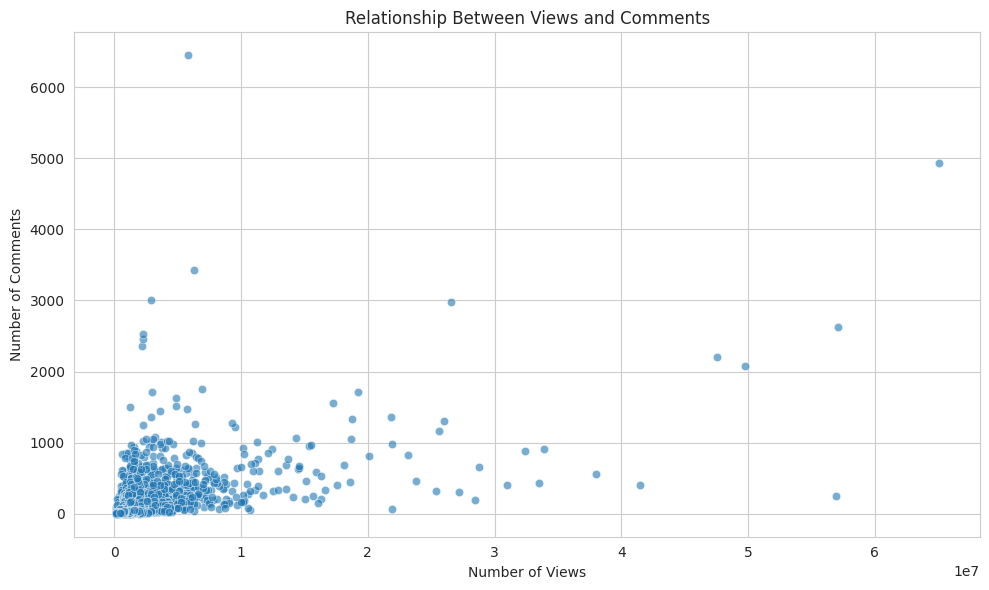

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=engagement_data,
    x="Views",
    y="Comments",
    alpha=0.6
)

plt.title("Relationship Between Views and Comments")
plt.xlabel("Number of Views")
plt.ylabel("Number of Comments")

plt.tight_layout()
plt.show()

In [26]:
if "Duration" in df.columns:

    df["Duration"] = pd.to_numeric(
        df["Duration"],
        errors="coerce"
    )

    display(df["Duration"].describe())

else:
    print("The column 'Duration' was not found.")

,Duration
count,4005.000000
mean,724.011236
std,361.775462
min,60.000000
25%,393.000000
50%,738.000000
75%,974.000000
max,3922.000000


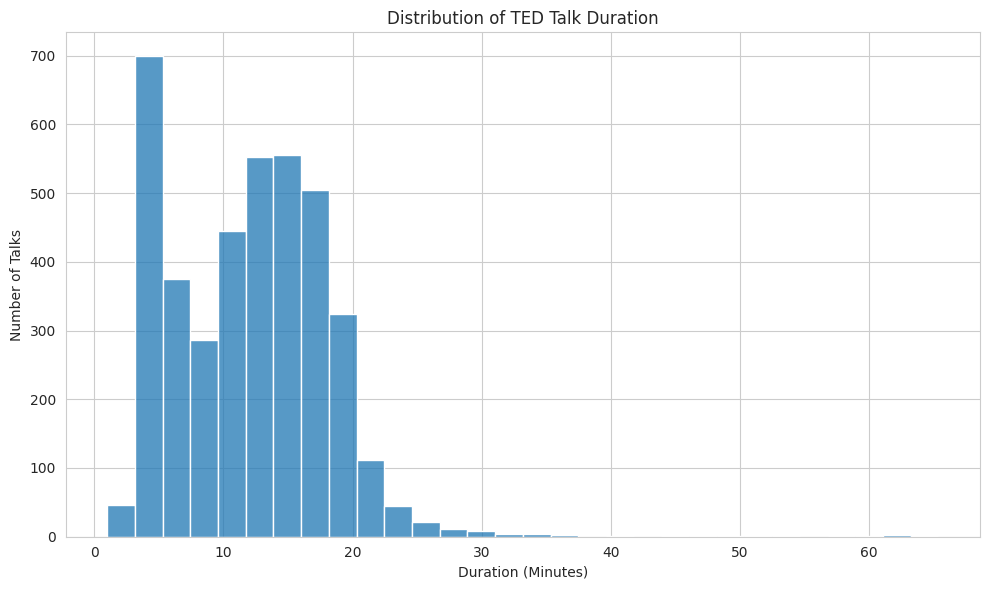

In [27]:
if "Duration" in df.columns:

    duration_minutes = df["Duration"].dropna() / 60

    plt.figure(figsize=(10, 6))

    sns.histplot(
        duration_minutes,
        bins=30
    )

    plt.title("Distribution of TED Talk Duration")
    plt.xlabel("Duration (Minutes)")
    plt.ylabel("Number of Talks")

    plt.tight_layout()
    plt.show()

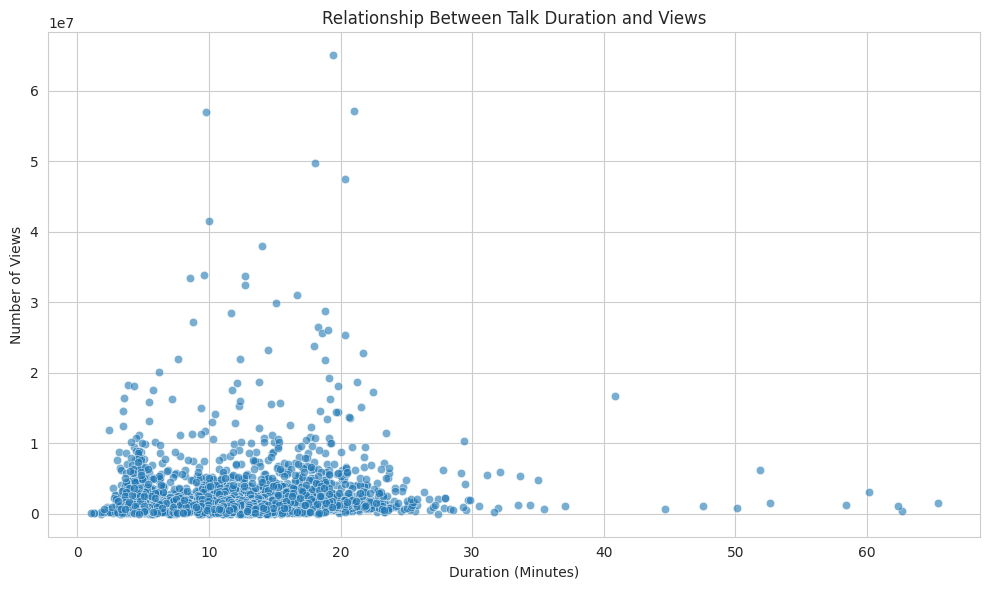

In [28]:
duration_views = df.dropna(
    subset=["Duration", "Views"]
).copy()

duration_views["Duration_Minutes"] = (
    duration_views["Duration"] / 60
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=duration_views,
    x="Duration_Minutes",
    y="Views",
    alpha=0.6
)

plt.title("Relationship Between Talk Duration and Views")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Views")

plt.tight_layout()
plt.show()

In [29]:
correlation = duration_views["Duration_Minutes"].corr(
    duration_views["Views"]
)

print(
    "Correlation between Duration and Views:",
    round(correlation, 4)
)

Correlation between Duration and Views: 0.0736


In [30]:
top_10_talks[columns_to_display].to_csv(
    "Top_10_Most_Viewed_TED_Talks.csv",
    index=False
)

print("Top 10 most-viewed talks exported successfully!")

Top 10 most-viewed talks exported successfully!


In [31]:
from google.colab import files

files.download("Top_10_Most_Viewed_TED_Talks.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>